In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [16]:
from sklearn.datasets import load_wine
wine= load_wine(as_frame=True)
df = wine.frame
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [17]:
df.describe()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258,0.938202
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474,0.775035
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000,0.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000,0.000000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000,1.000000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000,2.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000,2.000000


In [18]:
df.shape


(178, 14)

In [19]:
print(df.columns.tolist())

['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline', 'target']


In [20]:
df.isnull().sum()

alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
target                          0
dtype: int64

In [21]:
df['target'].value_counts()

target
1    71
0    59
2    48
Name: count, dtype: int64

In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
 13  targe

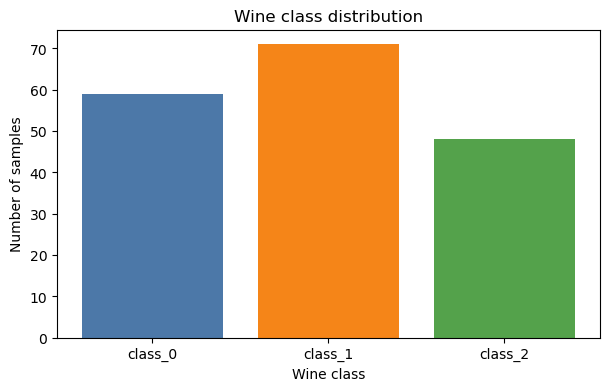

In [24]:
target_names = wine.target_names
class_counts = df['target'].value_counts().sort_index()

plt.figure(figsize=(7,4))
plt.bar(target_names,class_counts.values,color=["#4C78A8", "#F58518", "#54A24B"])
plt.title("Wine class distribution")
plt.xlabel("Wine class")
plt.ylabel("Number of samples")
plt.show()


In [25]:
print(target_names)

['class_0' 'class_1' 'class_2']


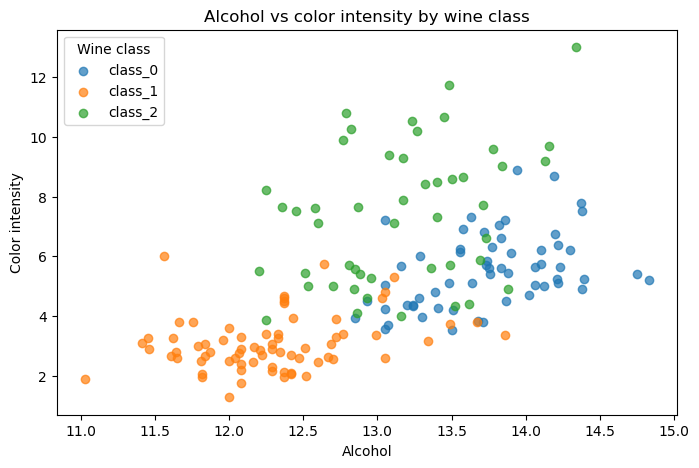

In [26]:
plt.figure(figsize=(8, 5))

for target, label in enumerate(target_names):
    subset = df[df["target"] == target]
    plt.scatter(
        subset["alcohol"],
        subset["color_intensity"],
        label=label,
        alpha=0.7
    )

plt.title("Alcohol vs color intensity by wine class")
plt.xlabel("Alcohol")
plt.ylabel("Color intensity")
plt.legend(title="Wine class")
plt.show()

In [27]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

In [32]:
X = df.drop(columns="target")
y = df["target"]

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state = 42,stratify=y)
print(X_train.shape[0])
print(X_test.shape[0],y_test.shape[0],y_train.shape[0])
      

142
36 36 142


In [34]:
model = Pipeline([
                ("scaler",StandardScaler()),("classifier",LogisticRegression(max_iter=2000))])
model.fit(X_train,y_train)

accuracy= model.score(X_test,y_test)
print("Test Accuracy is ",accuracy)

Test Accuracy is  0.9722222222222222


## Making Confusion Matrix

              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       0.93      1.00      0.97        14
     class_2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36



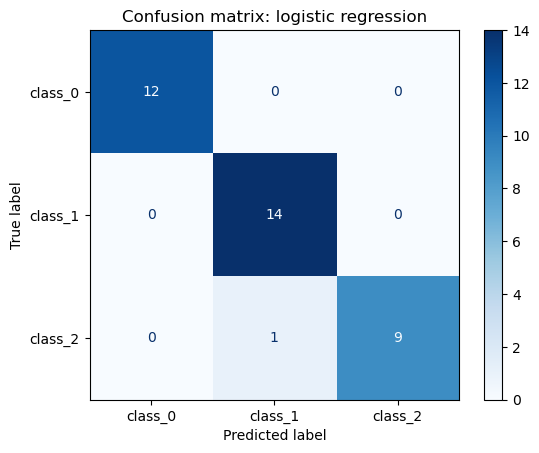

In [35]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

predictions = model.predict(X_test)

print(classification_report(y_test, predictions, target_names=target_names))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions,
    display_labels=target_names,
    cmap="Blues"
)
plt.title("Confusion matrix: logistic regression")
plt.show()

In [36]:
errors = X_test.copy()
errors["actual"] = y_test
errors["predicted"] = predictions
errors["correct"] = errors["actual"] == errors["predicted"]

errors[~errors["correct"]]

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,actual,predicted,correct
134,12.51,1.24,2.25,17.5,85.0,2.0,0.58,0.6,1.25,5.45,0.75,1.51,650.0,2,1,False


In [37]:
errors


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,actual,predicted,correct
10,14.10,2.16,2.30,18.0,105.0,2.95,3.32,0.22,2.38,5.75,1.25,3.17,1510.0,0,0,True
134,12.51,1.24,2.25,17.5,85.0,2.00,0.58,0.60,1.25,5.45,0.75,1.51,650.0,2,1,False
28,13.87,1.90,2.80,19.4,107.0,2.95,2.97,0.37,1.76,4.50,1.25,3.40,915.0,0,0,True
121,11.56,2.05,3.23,28.5,119.0,3.18,5.08,0.47,1.87,6.00,0.93,3.69,465.0,1,1,True
62,13.67,1.25,1.92,18.0,94.0,2.10,1.79,0.32,0.73,3.80,1.23,2.46,630.0,1,1,True
51,13.83,1.65,2.60,17.2,94.0,2.45,2.99,0.22,2.29,5.60,1.24,3.37,1265.0,0,0,True
7,14.06,2.15,2.61,17.6,121.0,2.60,2.51,0.31,1.25,5.05,1.06,3.58,1295.0,0,0,True
66,13.11,1.01,1.70,15.0,78.0,2.98,3.18,0.26,2.28,5.30,1.12,3.18,502.0,1,1,True
129,12.04,4.30,2.38,22.0,80.0,2.10,1.75,0.42,1.35,2.60,0.79,2.57,580.0,1,1,True
166,13.45,3.70,2.60,23.0,111.0,1.70,0.92,0.43,1.46,10.68,0.85,1.56,695.0,2,2,True


In [47]:
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier

knn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", KNeighborsClassifier(n_neighbors=5))
])

scores = cross_val_score(
    knn_model,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("Cross-validation scores:", scores)
print(f"Mean accuracy: {scores.mean():.2%}")
print(f"Variation: ±{scores.std():.2%}")

Cross-validation scores: [1.         0.89655172 0.96428571 1.         1.        ]
Mean accuracy: 97.22%
Variation: ±4.03%


In [50]:
results = []

for k in [1,3, 5, 7, 9, 11]:
    candidate_model = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(n_neighbors=k))
    ])

    scores = cross_val_score(
        candidate_model,
        X_train,
        y_train,
        cv=5,
        scoring="accuracy"
    )

    results.append({
        "k": k,
        "mean_accuracy": scores.mean(),
        "std_accuracy": scores.std()
    })

results_df = pd.DataFrame(results).sort_values(
    by="mean_accuracy",
    ascending=False
)

results_df

,k,mean_accuracy,std_accuracy
5,11,0.972167,0.040259
2,5,0.965025,0.037779
4,9,0.965025,0.037779
1,3,0.951232,0.034977
3,7,0.950985,0.035372
0,1,0.936700,0.013837


In [51]:
final_knn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", KNeighborsClassifier(n_neighbors=11))
])

final_knn_model.fit(X_train, y_train)

final_test_accuracy = final_knn_model.score(X_test, y_test)
print(f"Final KNN test accuracy: {final_test_accuracy:.2%}")

Final KNN test accuracy: 100.00%


In [52]:
comparison = pd.DataFrame({
    "model": ["Logistic Regression", "KNN (k=11)"],
    "test_accuracy": [accuracy, final_test_accuracy]
})

comparison

,model,test_accuracy
0,Logistic Regression,0.972222
1,KNN (k=11),1.000000


In [53]:
feature_importance = pd.DataFrame({
    "feature": X.columns,
    "coefficient_class_0": model.named_steps["classifier"].coef_[0],
    "coefficient_class_1": model.named_steps["classifier"].coef_[1],
    "coefficient_class_2": model.named_steps["classifier"].coef_[2],
})

feature_importance

,feature,coefficient_class_0,coefficient_class_1,coefficient_class_2
0,alcohol,0.717483,-0.861536,0.144053
1,malic_acid,0.167605,-0.512162,0.344557
2,ash,0.460126,-0.807256,0.347130
3,alcalinity_of_ash,-0.835063,0.466246,0.368817
4,magnesium,0.038629,-0.143768,0.105138
5,total_phenols,0.226480,0.062098,-0.288579
6,flavanoids,0.705264,0.198202,-0.903466
7,nonflavanoid_phenols,-0.108313,0.110509,-0.002196
8,proanthocyanins,0.125404,0.370369,-0.495773
9,color_intensity,0.220184,-1.096016,0.875831


In [55]:
feature_importance["overall_strength"] = (
    feature_importance[
        ["coefficient_class_0", "coefficient_class_1", "coefficient_class_2"]
    ]
    .abs()
    .max(axis=1)
)

feature_importance.sort_values(
    by="overall_strength",
    ascending=False
)

,feature,coefficient_class_0,coefficient_class_1,coefficient_class_2,overall_strength
9,color_intensity,0.220184,-1.096016,0.875831,1.096016
12,proline,0.926539,-1.009905,0.083366,1.009905
6,flavanoids,0.705264,0.198202,-0.903466,0.903466
0,alcohol,0.717483,-0.861536,0.144053,0.861536
3,alcalinity_of_ash,-0.835063,0.466246,0.368817,0.835063
2,ash,0.460126,-0.807256,0.347130,0.807256
10,hue,0.075344,0.630272,-0.705615,0.705615
11,od280/od315_of_diluted_wines,0.700187,-0.131291,-0.568896,0.700187
1,malic_acid,0.167605,-0.512162,0.344557,0.512162
8,proanthocyanins,0.125404,0.370369,-0.495773,0.495773
